# Assignment 3 · Parte 2 – Mapas del Perú

**Grupo 11** · Diplomado PUCP · Fundamentos de Python

**Pregunta:** ¿En qué zonas del país se concentraron las declaratorias de emergencia por lluvias (1 ene – 31 may 2024) y coinciden con las zonas donde más llovió?

## 1. Cargar los datos y las fronteras

In [1]:

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium

# dtype={"ubigeo": str} evita que '01' se convierta en el número 1
dataset = pd.read_csv("datos/dataset.csv", dtype={"ubigeo": str})

# Fronteras de los 25 departamentos. El código del departamento viene en la columna FIRST_IDDP
departamentos = gpd.read_file("datos/departamentos.geojson")
departamentos = departamentos.rename(columns={"FIRST_IDDP": "ubigeo"})[["ubigeo", "NOMBDEP", "geometry"]]

print("Sistema de coordenadas:", departamentos.crs)
print("Departamentos en el mapa:", departamentos.shape[0])
departamentos.head(3)

Sistema de coordenadas: EPSG:4326
Departamentos en el mapa: 25


,ubigeo,NOMBDEP,geometry
0,01,AMAZONAS,"POLYGON ((-77.75893 -6.96451, -77.84586 -6.976..."
1,02,ANCASH,"POLYGON ((-77.31749 -8.53015, -77.28903 -8.589..."
2,03,APURIMAC,"POLYGON ((-72.47177 -14.6614, -72.57725 -14.68..."


**Sobre el archivo de fronteras:** usamos `datos/departamentos.geojson` (25 departamentos, columna `FIRST_IDDP` con el ubigeo de 2 dígitos), tomado del repositorio `d2cml-ai/Data-Science-Python`. El de la sesión 7 solo trae el nombre del departamento, sin ubigeo, y no permite cruzar por código.

## 2. Cruce por ubigeo (como texto)

Antes de unir, verificamos que el ubigeo esté escrito igual en los dos lados: texto de 2 dígitos con el cero a la izquierda.

In [2]:
print("Mapa  :", departamentos["ubigeo"].dtype, "| ejemplo:", departamentos["ubigeo"].iloc[0])
print("Tabla :", dataset["ubigeo"].dtype, "| ejemplo:", dataset["ubigeo"].iloc[0])
print("Coinciden:", len(set(departamentos["ubigeo"]) & set(dataset["ubigeo"])), "de", len(dataset))

Mapa  : str | ejemplo: 01
Tabla : str | ejemplo: 01
Coinciden: 25 de 25


In [3]:
# how="left" desde el mapa para no perder ningún departamento.
# indicator=True agrega la columna _merge, que dice si cada fila encontró pareja.
mapa = departamentos.merge(dataset, on="ubigeo", how="left", indicator=True)

# Reporte de no cruces
sin_datos = mapa.loc[mapa["_merge"] == "left_only", "NOMBDEP"].tolist()
sin_mapa = sorted(set(dataset["ubigeo"]) - set(departamentos["ubigeo"]))
print("Departamentos del mapa sin datos:", sin_datos)
print("Ubigeos de la tabla que no están en el mapa:", sin_mapa)

# Comprobación: el total no debe cambiar después del cruce
print("Declaratorias en el mapa :", int(mapa["declaratorias"].sum()))
print("Declaratorias en la tabla:", int(dataset["declaratorias"].sum()))

mapa = mapa.drop(columns="_merge")

Departamentos del mapa sin datos: []
Ubigeos de la tabla que no están en el mapa: []
Declaratorias en el mapa : 100
Declaratorias en la tabla: 100


**Reporte del cruce:** cruzaron los 25 departamentos de 25. No quedó ninguno sin datos ni ningún ubigeo sin mapa, y el total de declaratorias (100) es el mismo antes y después del cruce.

In [4]:
print("Columnas disponibles:")
print(mapa.columns.tolist())

print("\nTotal de departamentos:", len(mapa))
print("Declaratorias totales:", mapa["declaratorias"].sum())
print("Departamentos sin datos:", mapa["declaratorias"].isna().sum())

display(mapa[["ubigeo", "NOMBDEP", "declaratorias"]].head())

Columnas disponibles:
['ubigeo', 'NOMBDEP', 'geometry', 'departamento', 'declaratorias', 'prorrogas', 'capital', 'latitud', 'longitud', 'lluvia_total_mm', 'dias_lluvia_fuerte']

Total de departamentos: 25
Declaratorias totales: 100
Departamentos sin datos: 0


,ubigeo,NOMBDEP,declaratorias
0,01,AMAZONAS,4
1,02,ANCASH,5
2,03,APURIMAC,7
3,04,AREQUIPA,7
4,05,AYACUCHO,7


2.3 Primera coropleta: total de declaratorias

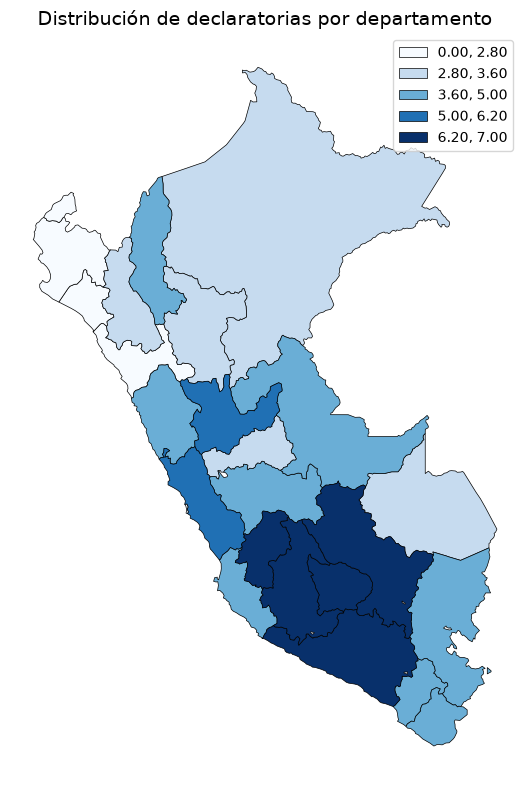

In [5]:
fig, ax = plt.subplots(figsize=(10, 8))

mapa.plot(
    column="declaratorias",
    cmap="Blues",
    scheme="Quantiles",
    k=5,
    legend=True,
    edgecolor="black",
    linewidth=0.5,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    },
    ax=ax
)

ax.set_title(
    "Distribución de declaratorias por departamento",
    fontsize=14
)
ax.axis("off")

plt.tight_layout()
plt.show()

Segunda coropleta: 

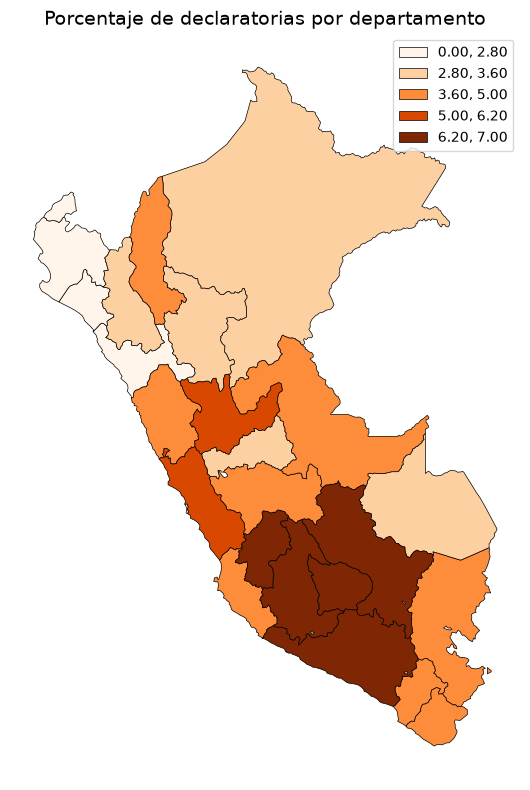

In [6]:
mapa["porcentaje_declaratorias"] = (
    mapa["declaratorias"]
    / mapa["declaratorias"].sum()
    * 100
)

fig, ax = plt.subplots(figsize=(10, 8))

mapa.plot(
    column="porcentaje_declaratorias",
    cmap="Oranges",
    scheme="Quantiles",
    k=5,
    legend=True,
    edgecolor="black",
    linewidth=0.5,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    },
    ax=ax
)

ax.set_title(
    "Porcentaje de declaratorias por departamento",
    fontsize=14
)
ax.axis("off")

plt.tight_layout()
plt.show()

Mapa interactivo:
Consultar información de cada departamento.

In [7]:
mapa_folium = mapa.to_crs(epsg=4326).copy()

In [8]:
m = folium.Map(
    location=[-9.19, -75.015],
    zoom_start=5,
    tiles="CartoDB positron"
)

In [9]:
folium.Choropleth(
    geo_data=mapa_folium,
    data=mapa_folium,
    columns=["ubigeo", "declaratorias"],
    key_on="feature.properties.ubigeo",
    fill_color="YlOrRd",
    fill_opacity=0.75,
    line_opacity=0.4,
    legend_name="Total de declaratorias",
    nan_fill_color="lightgrey"
).add_to(m)

folium.GeoJson(
    mapa_folium,
    tooltip=folium.GeoJsonTooltip(
        fields=["NOMBDEP", "declaratorias"],
        aliases=["Departamento:", "Declaratorias:"],
        localize=True
    ),
    name="Información departamental"
).add_to(m)

folium.LayerControl().add_to(m)

m

In [10]:
m.save("mapa_departamental.html")

Conclusiones: 
El mapa evidencia que las declaratorias no se distribuyen uniformemente entre los departamentos del Perú, sino que presentan diferencias territoriales en sus valores registrados.

La representación mediante coropletas permite identificar visualmente departamentos con valores relativamente altos y bajos de declaratorias, facilitando la comparación espacial de la información.

Las coropletas estáticas permiten agrupar los departamentos según su posición relativa en la distribución de los datos, mientras que la representación porcentual permite observar la contribución de cada departamento al total nacional.

La interpretación de los resultados depende de la calidad del cruce entre el dataset y los límites geográficos departamentales. Por ello, es importante distinguir los departamentos sin datos de aquellos que presentan un valor igual a cero.